<a href="https://colab.research.google.com/github/Iucasoa/Sistemas-Inteligentes/blob/main/problema4-arvore-decisao/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problema 4: Classificação de Risco de Crédito com Árvore de Decisão

Neste trabalho vamos construir uma árvore de decisão para classificar solicitantes de crédito em **bom pagador** e **mau pagador**, usando o dataset *Statlog (German Credit Data)*. O fluxo segue o notebook de árvores de decisão da disciplina (`08_Tree.ipynb`), adaptado ao problema: dados com atributos categóricos, classes desbalanceadas, escolha da profundidade por validação cruzada e interpretação das regras.

Inicialmente, vamos importar as bibliotecas:

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

Importando nosso dataset. Vamos usar a versão com rótulos legíveis (`credit-g`), como sugerido no enunciado. O alvo é transformado em 0 (bom pagador) e 1 (mau pagador):

In [2]:
dados = fetch_openml(name="credit-g", version=1, as_frame=True)
X = dados.data.copy()
y_raw = dados.target.copy()

# Alvo: 0 = bom pagador (good), 1 = mau pagador (bad)
assert set(y_raw.unique()) == {"good", "bad"}, "rótulos inesperados no alvo"
y = (y_raw == "bad").astype(int)

Verificando as dimensões, os valores ausentes e os tipos de dados:

In [3]:
print("Dimensão dos atributos:", X.shape)   # esperado: (1000, 20)
display(X.head())

print("\nValores ausentes (total):", int(X.isnull().sum().sum()))

print("\nTipos de dados:")
print(X.dtypes.value_counts())

Dimensão dos atributos: (1000, 20)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes



Valores ausentes (total): 0

Tipos de dados:
int64       7
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
category    1
Name: count, dtype: int64


**Tarefa 1.** Identificando quais atributos são numéricos e quais são categóricos:

In [4]:
cols_num = X.select_dtypes(include="number").columns.tolist()
cols_cat = X.select_dtypes(exclude="number").columns.tolist()

print(f"Atributos numéricos ({len(cols_num)}):", cols_num)
print(f"\nAtributos categóricos ({len(cols_cat)}):", cols_cat)

print("\nNúmero de categorias de cada atributo categórico:")
print(X[cols_cat].nunique().sort_values(ascending=False))

display(X[cols_num].describe().T)

Atributos numéricos (7): ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']

Atributos categóricos (13): ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']

Número de categorias de cada atributo categórico:
purpose                10
savings_status          5
credit_history          5
employment              5
checking_status         4
personal_status         4
property_magnitude      4
job                     4
other_parties           3
other_payment_plans     3
housing                 3
own_telephone           2
foreign_worker          2
dtype: int64


,count,mean,std,min,25%,50%,75%,max
duration,1000.0,20.903,12.058814,4.0,12.0,18.0,24.00,72.0
credit_amount,1000.0,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
installment_commitment,1000.0,2.973,1.118715,1.0,2.0,3.0,4.00,4.0
residence_since,1000.0,2.845,1.103718,1.0,2.0,3.0,4.00,4.0
age,1000.0,35.546,11.375469,19.0,27.0,33.0,42.00,75.0
existing_credits,1000.0,1.407,0.577654,1.0,1.0,1.0,2.00,4.0
num_dependents,1000.0,1.155,0.362086,1.0,1.0,1.0,1.00,2.0


A `sklearn` exige entradas numéricas, e os atributos categóricos são **nominais** (não há ordem entre as categorias). Por isso vamos usar o *one-hot encoding*, que cria uma coluna binária para cada categoria:

In [5]:
# One-hot encoding dos atributos categóricos
X_enc = pd.get_dummies(X, columns=cols_cat, dtype=int)
print("Dimensão após o one-hot encoding:", X_enc.shape)

Dimensão após o one-hot encoding: (1000, 61)


Avaliando o balanceamento entre as classes:

Classe 0 (bom pagador): 700 (70.0%)
Classe 1 (mau pagador): 300 (30.0%)


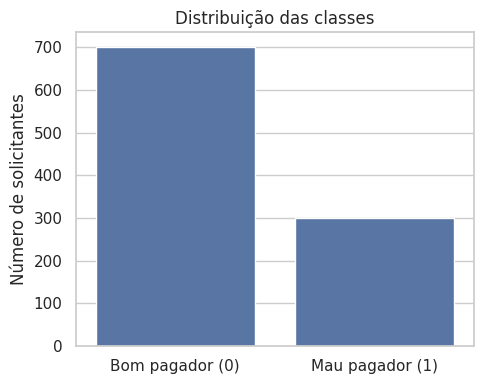

In [6]:
contagem = y.value_counts().sort_index()
proporcao = (y.value_counts(normalize=True).sort_index() * 100).round(1)
print("Classe 0 (bom pagador):", contagem[0], f"({proporcao[0]}%)")
print("Classe 1 (mau pagador):", contagem[1], f"({proporcao[1]}%)")

plt.figure(figsize=(5, 4))
sns.barplot(x=["Bom pagador (0)", "Mau pagador (1)"], y=contagem.values)
plt.ylabel("Número de solicitantes")
plt.title("Distribuição das classes")
plt.tight_layout()
plt.show()

**Tarefa 3.** Realizando a divisão em conjunto de treino (80%) e teste (20%), de forma **estratificada**. Lembrando que, para árvores de decisão, não é necessário normalizar os atributos (**Tarefa 2**).

Também vamos criar um *baseline*: um classificador que sempre prevê a classe majoritária (bom pagador), para entender o impacto do desbalanceamento 70%/30% sobre a acurácia:

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X_enc, y, test_size=0.20, random_state=42, stratify=y
)
print("Treino:", len(X_train), "| Teste:", len(X_test))
print("\nProporção de mau pagador no treino:", round(y_train.mean(), 4))
print("Proporção de mau pagador no teste: ", round(y_test.mean(), 4))

# Baseline: classificador que sempre prevê "bom pagador"
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
y_base = base.predict(X_test)
print(f"\nAcurácia do baseline no teste: {accuracy_score(y_test, y_base):.4f}")
print(classification_report(y_test, y_base, target_names=["Bom (0)", "Mau (1)"], zero_division=0))

Treino: 800 | Teste: 200

Proporção de mau pagador no treino: 0.3
Proporção de mau pagador no teste:  0.3

Acurácia do baseline no teste: 0.7000
              precision    recall  f1-score   support

     Bom (0)       0.70      1.00      0.82       140
     Mau (1)       0.00      0.00      0.00        60

    accuracy                           0.70       200
   macro avg       0.35      0.50      0.41       200
weighted avg       0.49      0.70      0.58       200



**Tarefa 4.** Para controlar a complexidade da árvore, vamos avaliar várias profundidades máximas (2, 3, 5, 7, 10 e sem limite) por **validação cruzada de 5 folds** sobre o conjunto de treino, primeiro com o critério de Gini e depois com a entropia:

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
profundidades = [2, 3, 5, 7, 10, None]
linhas = []

for criterio in ["gini", "entropy"]:
    for d in profundidades:
        arvore = DecisionTreeClassifier(criterion=criterio, max_depth=d, random_state=42)
        r = cross_validate(arvore, X_train, y_train, cv=cv,
                           scoring="accuracy", return_train_score=True)
        linhas.append((criterio, "sem limite" if d is None else str(d),
                       r["train_score"].mean(), r["test_score"].mean(), r["test_score"].std()))

tabela = pd.DataFrame(linhas, columns=["criterio", "profundidade", "acc_treino", "acc_validacao", "desvio"])
display(tabela.round(4))

,criterio,profundidade,acc_treino,acc_validacao,desvio
0,gini,2,0.7081,0.6888,0.0139
1,gini,3,0.7453,0.6975,0.0353
2,gini,5,0.8034,0.6950,0.0228
3,gini,7,0.8794,0.7188,0.0274
4,gini,10,0.9575,0.6862,0.0248
5,gini,sem limite,1.0000,0.6850,0.0226
6,entropy,2,0.7069,0.6938,0.0125
7,entropy,3,0.7359,0.6988,0.0352
8,entropy,5,0.7944,0.7162,0.0469
9,entropy,7,0.8584,0.7175,0.0329


Plotando, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade (um painel para cada critério). A linha pontilhada é o baseline de 70%:

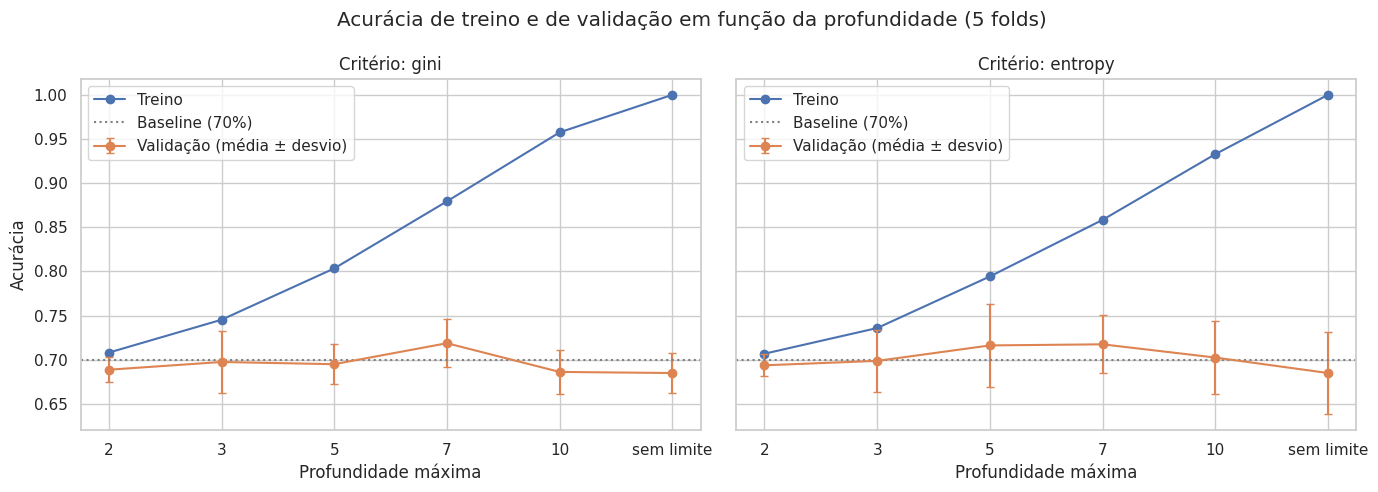

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for a, criterio in zip(ax, ["gini", "entropy"]):
    t = tabela[tabela["criterio"] == criterio]
    a.plot(t["profundidade"], t["acc_treino"], marker="o", label="Treino")
    a.errorbar(t["profundidade"], t["acc_validacao"], yerr=t["desvio"],
               marker="o", capsize=3, label="Validação (média ± desvio)")
    a.axhline(0.70, color="gray", linestyle=":", label="Baseline (70%)")
    a.set_xlabel("Profundidade máxima")
    a.set_title(f"Critério: {criterio}")
    a.legend()
ax[0].set_ylabel("Acurácia")

fig.suptitle("Acurácia de treino e de validação em função da profundidade (5 folds)")
fig.tight_layout()
fig.savefig("curva_profundidade.png", dpi=300)
plt.show()

Escolhendo a profundidade com a maior acurácia média de validação (critério Gini) e comparando com a melhor profundidade da entropia:

In [10]:
for criterio in ["gini", "entropy"]:
    t = tabela[tabela["criterio"] == criterio].reset_index(drop=True)
    melhor = t.loc[t["acc_validacao"].idxmax()]
    print(f"{criterio}: melhor profundidade = {melhor['profundidade']} "
          f"(validação {melhor['acc_validacao']:.4f} ± {melhor['desvio']:.4f})")

t_gini = tabela[tabela["criterio"] == "gini"].reset_index(drop=True)
melhor_gini = t_gini.loc[t_gini["acc_validacao"].idxmax(), "profundidade"]
profundidade_otima = None if melhor_gini == "sem limite" else int(melhor_gini)
print("\nProfundidade escolhida (critério Gini):", melhor_gini)

gini: melhor profundidade = 7 (validação 0.7188 ± 0.0274)
entropy: melhor profundidade = 7 (validação 0.7175 ± 0.0329)

Profundidade escolhida (critério Gini): 7


(Opcional) Verificando experimentalmente que a normalização não altera a árvore. Vamos padronizar apenas os atributos numéricos e comparar as previsões:

In [11]:
from sklearn.preprocessing import StandardScaler

# Padroniza apenas os atributos numéricos (as colunas one-hot ficam como estão).
# Serve só para ilustrar a invariância da árvore; não é usado para escolher hiperparâmetros.
escala = StandardScaler().fit(X_train[cols_num])
X_train_pad, X_test_pad = X_train.copy(), X_test.copy()
X_train_pad[cols_num] = escala.transform(X_train[cols_num])
X_test_pad[cols_num] = escala.transform(X_test[cols_num])

arv_bruta = DecisionTreeClassifier(criterion="gini", max_depth=profundidade_otima, random_state=42).fit(X_train, y_train)
arv_pad = DecisionTreeClassifier(criterion="gini", max_depth=profundidade_otima, random_state=42).fit(X_train_pad, y_train)

p_bruta, p_pad = arv_bruta.predict(X_test), arv_pad.predict(X_test_pad)
print(f"Acurácia no teste sem padronização: {accuracy_score(y_test, p_bruta):.4f}")
print(f"Acurácia no teste com padronização: {accuracy_score(y_test, p_pad):.4f}")
print("Previsões idênticas nos dois casos:", bool((p_bruta == p_pad).all()))

Acurácia no teste sem padronização: 0.6650
Acurácia no teste com padronização: 0.6650
Previsões idênticas nos dois casos: True


**Tarefa 5.** Vamos criar o modelo de árvore com a profundidade escolhida:

In [12]:
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=profundidade_otima,   # profundidade escolhida por validação cruzada
    min_samples_split=2,            # mínimo de amostras necessárias para fazer um split
    min_samples_leaf=1,             # mínimo de amostras para considerar um nó como folha
    random_state=42,
)

E após isso, vamos treinar nosso modelo:

In [13]:
model.fit(X_train, y_train)
print("Profundidade real da árvore:", model.get_depth(), "| Número de folhas:", model.get_n_leaves())

Profundidade real da árvore: 7 | Número de folhas: 59


Calculando a importância dos atributos (redução total de impureza trazida por cada um):

In [14]:
importancias = pd.Series(model.feature_importances_, index=X_enc.columns).sort_values(ascending=False)
print("Atributos mais importantes (somente os com importância > 0):")
print(importancias[importancias > 0].round(4))

Atributos mais importantes (somente os com importância > 0):
checking_status_no checking                      0.1886
duration                                         0.1345
credit_amount                                    0.1244
purpose_education                                0.0485
age                                              0.0416
installment_commitment                           0.0391
employment_1<=X<4                                0.0362
savings_status_<100                              0.0362
other_payment_plans_bank                         0.0278
savings_status_>=1000                            0.0260
employment_<1                                    0.0255
property_magnitude_car                           0.0245
purpose_furniture/equipment                      0.0230
property_magnitude_no known property             0.0230
savings_status_100<=X<500                        0.0194
property_magnitude_life insurance                0.0177
residence_since                            

Podemos visualizar a árvore utilizando a função `plot_tree`. Como a árvore completa é grande, a figura mostra apenas os 4 primeiros níveis:

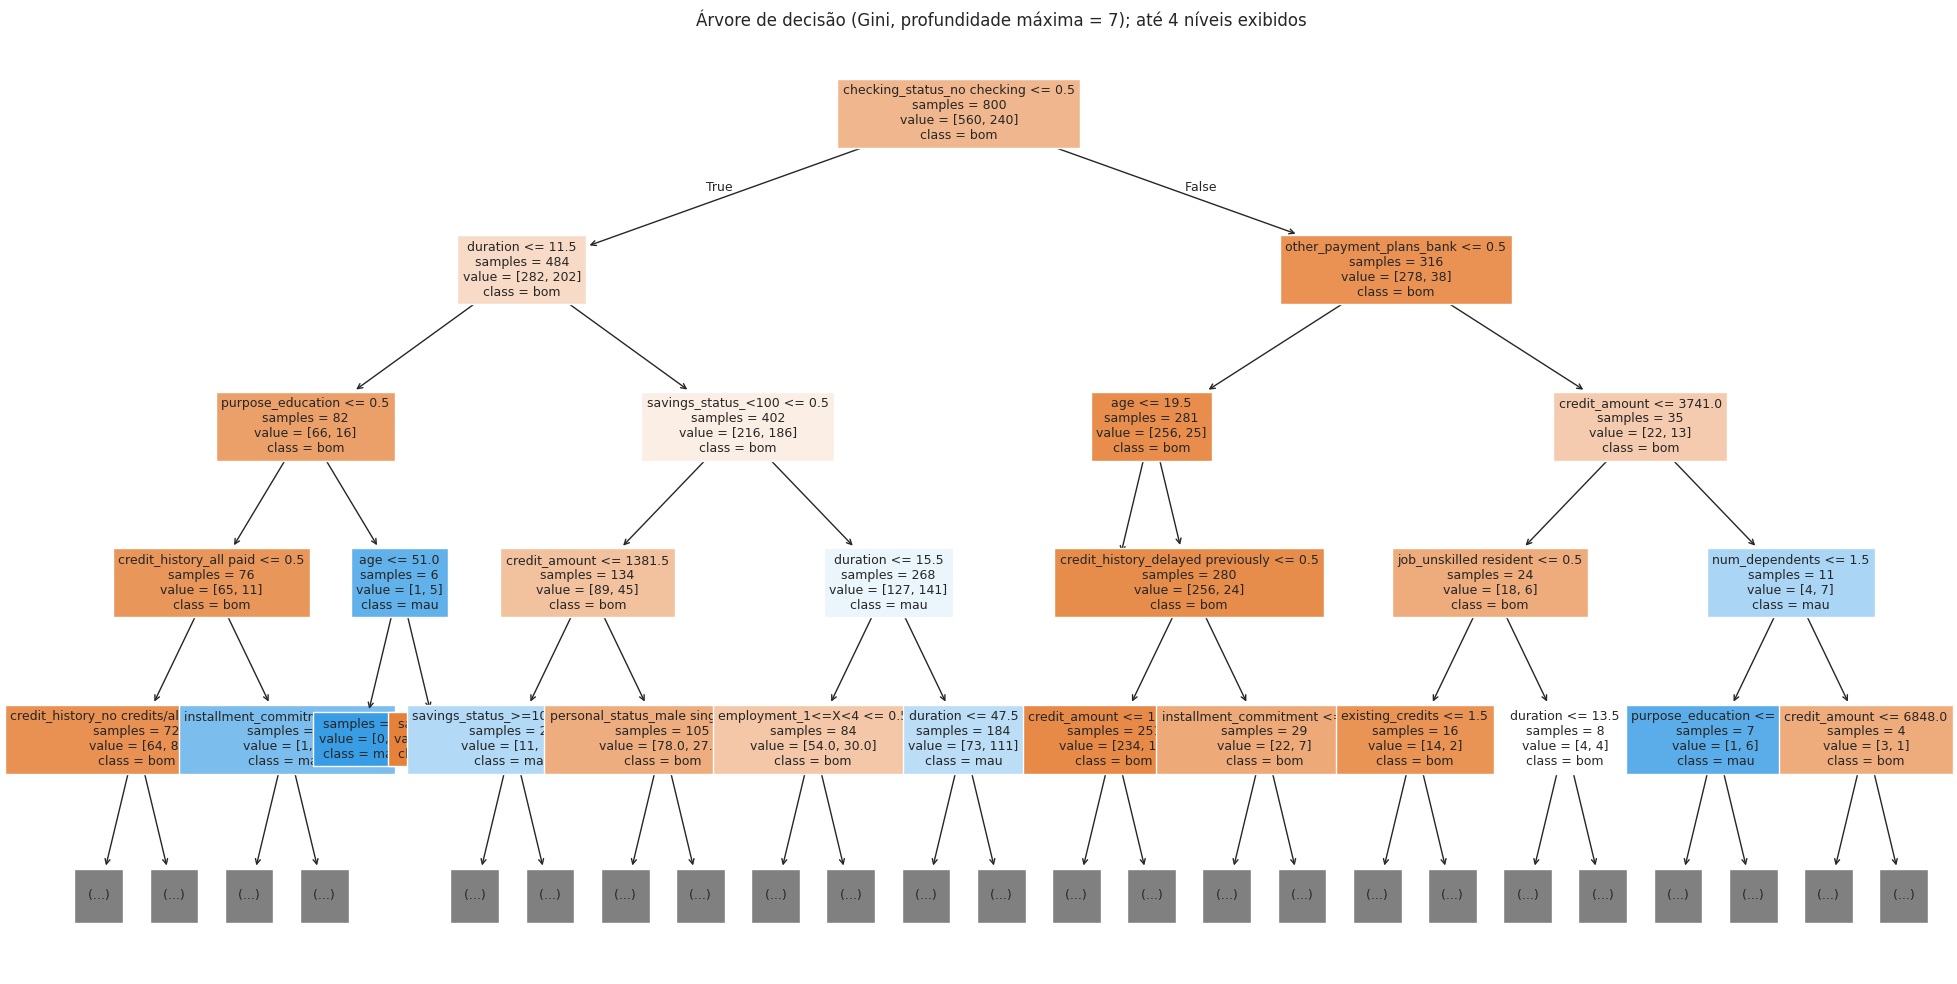

In [15]:
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    model,
    feature_names=list(X_enc.columns),
    class_names=["bom", "mau"],
    filled=True,
    impurity=False,
    max_depth=4,
    fontsize=9,
    ax=ax,
)
ax.set_title(f"Árvore de decisão (Gini, profundidade máxima = {profundidade_otima}); até 4 níveis exibidos")
fig.tight_layout()
fig.savefig("arvore_decisao.png", dpi=300)
plt.show()

Podemos também visualizar a estrutura em forma de árvore textual, utilizando a função `export_text`:

In [16]:
print(
    export_text(
        model,
        feature_names=list(X_enc.columns),
        class_names=["bom", "mau"],
    )
)

|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- purpose_education <= 0.50
|   |   |   |--- credit_history_all paid <= 0.50
|   |   |   |   |--- credit_history_no credits/all paid <= 0.50
|   |   |   |   |   |--- housing_own <= 0.50
|   |   |   |   |   |   |--- existing_credits <= 1.50
|   |   |   |   |   |   |   |--- class: bom
|   |   |   |   |   |   |--- existing_credits >  1.50
|   |   |   |   |   |   |   |--- class: bom
|   |   |   |   |   |--- housing_own >  0.50
|   |   |   |   |   |   |--- employment_1<=X<4 <= 0.50
|   |   |   |   |   |   |   |--- class: bom
|   |   |   |   |   |   |--- employment_1<=X<4 >  0.50
|   |   |   |   |   |   |   |--- class: bom
|   |   |   |   |--- credit_history_no credits/all paid >  0.50
|   |   |   |   |   |--- class: mau
|   |   |   |--- credit_history_all paid >  0.50
|   |   |   |   |--- installment_commitment <= 3.00
|   |   |   |   |   |--- class: mau
|   |   |   |   |--- installment_commitment >  3.00
|   |  

Agora vamos achar a folha com o **maior número de amostras de mau pagador** (no treino) e o caminho da raiz até ela. Nas colunas *one-hot*, o teste `<= 0.50` significa "não pertence à categoria" e `> 0.50` significa "pertence":

In [17]:
folhas = model.apply(X_train)
contagem_folhas = pd.DataFrame({"folha": folhas, "mau": y_train.values}).groupby("folha")["mau"].agg(["sum", "count"])
contagem_folhas.columns = ["mau", "total"]
contagem_folhas["bom"] = contagem_folhas["total"] - contagem_folhas["mau"]

folha_alvo = contagem_folhas["mau"].idxmax()
info = contagem_folhas.loc[folha_alvo]
print(f"Folha {folha_alvo}: {int(info['mau'])} maus e {int(info['bom'])} bons "
      f"({100 * info['mau'] / info['total']:.1f}% de maus)")

arv = model.tree_

def caminho_ate(no_alvo):
    def busca(no, trilha):
        if no == no_alvo:
            return trilha
        if arv.children_left[no] == -1:
            return None
        nome, lim = X_enc.columns[arv.feature[no]], arv.threshold[no]
        r = busca(arv.children_left[no], trilha + [(nome, "<=", lim)])
        if r is not None:
            return r
        return busca(arv.children_right[no], trilha + [(nome, ">", lim)])
    return busca(0, [])

print("\nRegra (da raiz até essa folha):")
for nome, op, lim in caminho_ate(folha_alvo):
    print(f"  {nome} {op} {lim:.2f}")

Folha 67: 44 maus e 53 bons (45.4% de maus)

Regra (da raiz até essa folha):
  checking_status_no checking <= 0.50
  duration > 11.50
  savings_status_<100 > 0.50
  duration > 15.50
  duration <= 47.50
  credit_amount > 2321.00
  credit_amount <= 8015.50


**Tarefa 6.** Calculando a acurácia e as métricas por classe no conjunto de teste:

In [18]:
y_pred = model.predict(X_test)
print(f"Acurácia (teste): {accuracy_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Bom (0)", "Mau (1)"], zero_division=0))

Acurácia (teste): 0.6650

              precision    recall  f1-score   support

     Bom (0)       0.75      0.78      0.76       140
     Mau (1)       0.44      0.40      0.42        60

    accuracy                           0.67       200
   macro avg       0.59      0.59      0.59       200
weighted avg       0.66      0.67      0.66       200



Bem como a matriz de confusão:

Matriz de confusão (teste):
          prev bom  prev mau
real bom       109        31
real mau        36        24


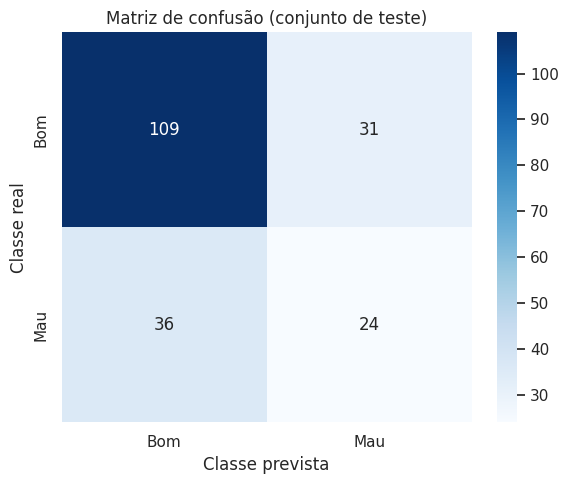

In [19]:
cm = confusion_matrix(y_test, y_pred)
print("Matriz de confusão (teste):")
print(pd.DataFrame(cm, index=["real bom", "real mau"], columns=["prev bom", "prev mau"]))

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Bom", "Mau"], yticklabels=["Bom", "Mau"])
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.title("Matriz de confusão (conjunto de teste)")
plt.tight_layout()
plt.savefig("matriz_confusao.png", dpi=300)
plt.show()

(Opcional) Ajuste para reduzir o erro mais grave (falso negativo do mau pagador): ponderação de classes. Esta é uma demonstração do efeito; ela **não** é usada para escolher hiperparâmetros, pois isso seria olhar o conjunto de teste:

In [20]:
model_pond = DecisionTreeClassifier(
    criterion="gini",
    max_depth=profundidade_otima,
    min_samples_split=2,
    min_samples_leaf=1,
    class_weight="balanced",
    random_state=42,
)
model_pond.fit(X_train, y_train)
y_pred_pond = model_pond.predict(X_test)

print(f"Acurácia (teste, class_weight='balanced'): {accuracy_score(y_test, y_pred_pond):.4f}\n")
print(classification_report(y_test, y_pred_pond, target_names=["Bom (0)", "Mau (1)"], zero_division=0))
print(pd.DataFrame(confusion_matrix(y_test, y_pred_pond),
                   index=["real bom", "real mau"], columns=["prev bom", "prev mau"]))

Acurácia (teste, class_weight='balanced'): 0.5850

              precision    recall  f1-score   support

     Bom (0)       0.76      0.59      0.67       140
     Mau (1)       0.37      0.57      0.45        60

    accuracy                           0.58       200
   macro avg       0.57      0.58      0.56       200
weighted avg       0.65      0.58      0.60       200

          prev bom  prev mau
real bom        83        57
real mau        26        34


Baixando as figuras para usar no relatório (o armazenamento do Colab é temporário):

In [22]:
from google.colab import files
files.download("curva_profundidade.png")
files.download("arvore_decisao.png")
files.download("matriz_confusao.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>